# P1 — Robustness ranking re-analysis
Session 2 — 25.11.2026 — data download, loading, sanity check for cifr100

In [ ]:
# A6 — Cell 20: download and place the CIFAR-100 and ImageNet16-120 accuracy files (run once)
from google.colab import drive
drive.mount('/content/drive')
!test -d robustness-data || cp -r /content/drive/MyDrive/P1/robustness-data .
import zipfile, os, shutil
SHARE = "bBnaTnTZWtZqMnE"
BASE = "https://nextcloud.mpi-klsb.mpg.de/public.php/webdav"
for z, d in [("cifar100-accuracies.zip", "cifar100"), ("imagenet-accuracies.zip", "ImageNet16-120")]:
    !curl -s -f -u "{SHARE}:" -o /content/{z} {BASE}/{z}
    os.makedirs(f"robustness-data/{d}", exist_ok=True)
    with zipfile.ZipFile(f"/content/{z}") as zf:
        names = [n for n in zf.namelist() if n.endswith("_accuracy.json")]
        for n in names:
            with zf.open(n) as src, open(f"robustness-data/{d}/{os.path.basename(n)}", "wb") as dst:
                shutil.copyfileobj(src, dst)
    missing = [k for k in ["clean", "fgsm@Linf", "pgd@Linf", "aa_apgd-ce@Linf", "aa_square@Linf"] if not os.path.isfile(f"robustness-data/{d}/{k}_accuracy.json")]
    print(d, "|", len(names), "accuracy files | missing:", missing)
!cp -r robustness-data/cifar100 robustness-data/ImageNet16-120 /content/drive/MyDrive/P1/robustness-data/

Mounted at /content/drive
cifar100 | 20 accuracy files | missing: []
ImageNet16-120 | 5 accuracy files | missing: []


In [ ]:
# Cell 0-setup
from google.colab import drive
drive.mount('/content/drive')
!test -d robustness-data || cp -r /content/drive/MyDrive/P1/robustness-data .
!test -d robustness-dataset || git clone -q https://github.com/steffen-jung/robustness-dataset
import sys
sys.path.append("robustness-dataset")
from robustness_dataset import RobustnessDataset
import pandas as pd

DATASET = "cifar100"          # A6: "cifar100", then "ImageNet16-120"
data = RobustnessDataset(path="robustness-data")
KEYS = ["clean", "fgsm@Linf", "pgd@Linf", "aa_apgd-ce@Linf", "aa_square@Linf"]
r = data.query(data=DATASET, key=KEYS, measure="accuracy")[DATASET]

def acc(attack, eps):
    i = data.meta["epsilons"][attack].index(eps)
    return {a: v[i] for a, v in r[attack]["accuracy"].items()}

df = pd.DataFrame({
    "clean":    pd.Series(r["clean"]["accuracy"]),
    "fgsm_0.5": pd.Series(acc("fgsm@Linf", 0.5)),
    "fgsm_1":   pd.Series(acc("fgsm@Linf", 1.0)),
    "pgd_1":    pd.Series(acc("pgd@Linf", 1.0)),
    "apgd_1":   pd.Series(acc("aa_apgd-ce@Linf", 1.0)),
    "square_1": pd.Series(acc("aa_square@Linf", 1.0)),
    "apgd_4":   pd.Series(acc("aa_apgd-ce@Linf", 4.0)),
    "square_4": pd.Series(acc("aa_square@Linf", 4.0)),
}).loc[data.non_isomorph_ids]
print(df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(6466, 8)


In [ ]:
# A4 — Cell 10: settings and helper functions
import numpy as np
from scipy.stats import kendalltau, spearmanr

N_CLASSES = 100                                   # CIFAR-10 (A6: 100, then 120)
CHEAP   = ["clean", "fgsm_0.5", "fgsm_1", "pgd_1"]
TARGETS = ["apgd_1", "square_1", "apgd_4", "square_4"]
FRACS   = [0.01, 0.05, 0.10]
OUT     = "/content/drive/MyDrive/P1/"           # results are saved here
TAG     = DATASET                                # used in file names

A = df[df["clean"] >= 2 / N_CLASSES]             # analysis set (plan §3)
print("analysis set:", len(A), "| excluded:", len(df) - len(A))

def topk_weights(x, k):
    kth = np.sort(x)[::-1][k - 1]
    above, tied = x > kth, x == kth
    w = above.astype(float)
    w[tied] = (k - above.sum()) / tied.sum()
    return w

def pair_metrics(c, t, clean):
    out = {"tau": kendalltau(c, t).statistic, "rho": spearmanr(c, t).statistic}
    for f in FRACS:
        k = max(1, round(f * len(c)))
        wc, wt = topk_weights(c, k), topk_weights(t, k)
        out[f"ov{round(f * 100)}"] = wc @ wt / k
        if f == 0.05:
            out["top5_T_byC"] = 100 * (wc @ t) / k
            out["top5_T_byT"] = 100 * (wt @ t) / k
            out["top5_clean_byC"] = 100 * (wc @ clean) / k
    return out

analysis set: 6461 | excluded: 5


In [ ]:
# A6 — Cell 21: data integrity check + best architectures (descriptive, outside the frozen analysis)
import json
print("rows:", len(df), "| unique IDs:", df.index.is_unique, "| missing values:", int(df.isna().sum().sum()))
print("min:", df.min().min(), "| max:", df.max().max())

aid = df.index[0]                                      # one architecture, checked against the raw files
def raw(key):
    with open(f"robustness-data/{DATASET}/{key}_accuracy.json") as f:
        return json.load(f)[DATASET][key]["accuracy"][aid]
for key, cols in [("clean", ["clean"]), ("fgsm@Linf", ["fgsm_0.5", "fgsm_1"]), ("pgd@Linf", ["pgd_1"]),
                  ("aa_apgd-ce@Linf", ["apgd_1", "apgd_4"]), ("aa_square@Linf", ["square_1", "square_4"])]:
    print(aid, key, "| eps:", data.meta["epsilons"].get(key), "| raw:", raw(key), "| df:", df.loc[aid, cols].tolist())

print(df[df["clean"] < 2 / N_CLASSES])                 # the excluded architectures
best = sorted(set(A[c].idxmax() for c in df.columns))  # best architecture per column (first one if tied)
print(A.loc[best].round(3))

rows: 6466 | unique IDs: True | missing values: 0
min: 0.0 | max: 0.736
0 clean | eps: None | raw: 0.519 | df: [0.519]
0 fgsm@Linf | eps: [0.1, 0.5, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 255.0] | raw: [0.453, 0.239, 0.119, 0.052, 0.038, 0.033, 0.031, 0.029, 0.027, 0.026, 0.012] | df: [0.239, 0.119]
0 pgd@Linf | eps: [0.1, 0.5, 1.0, 2.0, 3.0, 4.0, 8.0] | raw: [0.459, 0.229, 0.074, 0.007, 0.001, 0.0, 0.0] | df: [0.074]
0 aa_apgd-ce@Linf | eps: [0.1, 0.5, 1.0, 2.0, 3.0, 4.0, 8.0] | raw: [0.45, 0.182, 0.034, 0.002, 0.0, 0.0, 0.0] | df: [0.034, 0.0]
0 aa_square@Linf | eps: [0.1, 0.5, 1.0, 2.0, 3.0, 4.0, 8.0] | raw: [0.502, 0.385, 0.248, 0.1, 0.042, 0.023, 0.003] | df: [0.248, 0.023]
     clean  fgsm_0.5  fgsm_1  pgd_1  apgd_1  square_1  apgd_4  square_4
10    0.01      0.01    0.01   0.01    0.01      0.01    0.01      0.01
12    0.01      0.01    0.01   0.01    0.01      0.01    0.01      0.01
74    0.01      0.01    0.01   0.01    0.01      0.01    0.01      0.01
172   0.01      0.01   

In [ ]:
# A4 — Cell 11: point estimates for the 16 pairs
clean = A["clean"].to_numpy()
rows = []
for t in TARGETS:
    T = A[t].to_numpy()
    for c in CHEAP:
        C = A[c].to_numpy()
        m = pair_metrics(C, T, clean)
        m["regret_pp"] = 100 * (T.max() - T[C == C.max()].mean())
        for f in FRACS:
            k = max(1, round(f * len(C)))
            m[f"tiedC_{round(f * 100)}"] = int((C == np.sort(C)[::-1][k - 1]).sum())
            m[f"tiedT_{round(f * 100)}"] = int((T == np.sort(T)[::-1][k - 1]).sum())
        rows.append({"target": t, "cheap": c, **m})
point = pd.DataFrame(rows).set_index(["target", "cheap"])
assert (point["top5_T_byT"] >= point["top5_T_byC"] - 1e-9).all()
point.to_csv(f"{OUT}a4_point_{TAG}.csv")
print(point.round(3).to_string())

                     tau    rho    ov1    ov5  top5_T_byC  top5_T_byT  top5_clean_byC   ov10  regret_pp  tiedC_1  tiedT_1  tiedC_5  tiedT_5  tiedC_10  tiedT_10
target   cheap                                                                                                                                                 
apgd_1   clean    -0.398 -0.558  0.000  0.000       2.144      19.641          71.339  0.002      23.85       11        5       48        2        45        12
         fgsm_0.5  0.385  0.529  0.142  0.294      11.564      19.641          62.826  0.477      14.20        3        5       13        2        29        12
         fgsm_1    0.264  0.377  0.431  0.407      12.266      19.641          61.200  0.375       0.00        5        5       24        2        33        12
         pgd_1     0.884  0.975  0.794  0.954      19.550      19.641          46.904  0.927       0.00        4        5        4        2        15        12
square_1 clean    -0.195 -0.292  0.000  

In [ ]:
# A4 — Cell 12: paired bootstrap (B = 1000, seed 0)
rng = np.random.default_rng(0)
n, B = len(A), 1000
X = {col: A[col].to_numpy() for col in CHEAP + TARGETS}
boot = []
for b in range(B):
    i = rng.integers(0, n, n)                    # the same rows for every pair = paired
    for t in TARGETS:
        for c in CHEAP:
            boot.append({"b": b, "target": t, "cheap": c, **pair_metrics(X[c][i], X[t][i], X["clean"][i])})
    if b % 100 == 0:
        print(b, end=" ")
boot = pd.DataFrame(boot)
boot.to_csv(f"{OUT}a4_bootstrap_{TAG}.csv", index=False)
print("\n", boot.shape)

0 100 200 300 400 500 600 700 800 900 
 (16000, 11)


In [ ]:
# A4 — Cell 13: point estimate [95% percentile interval]
METRICS = ["tau", "rho", "ov1", "ov5", "ov10", "top5_T_byC", "top5_T_byT", "top5_clean_byC"]
g = boot.groupby(["target", "cheap"])[METRICS]
lo, hi = g.quantile(0.025), g.quantile(0.975)
summary = pd.DataFrame(index=point.index)
for m in METRICS:
    summary[m] = [f"{point.loc[ix, m]:.2f} [{lo.loc[ix, m]:.2f}, {hi.loc[ix, m]:.2f}]" for ix in point.index]
summary["regret_pp"] = point["regret_pp"].round(1)
summary.to_csv(f"{OUT}a4_summary_{TAG}.csv")
print(summary.to_string())

                                    tau                   rho                ov1                ov5               ov10            top5_T_byC            top5_T_byT        top5_clean_byC  regret_pp
target   cheap                                                                                                                                                                                     
apgd_1   clean     -0.40 [-0.41, -0.38]  -0.56 [-0.58, -0.54]  0.00 [0.00, 0.00]  0.00 [0.00, 0.00]  0.00 [0.00, 0.00]     2.14 [2.05, 2.24]  19.64 [18.83, 20.37]  71.34 [71.24, 71.44]       23.8
         fgsm_0.5     0.38 [0.37, 0.40]     0.53 [0.51, 0.55]  0.14 [0.06, 0.23]  0.29 [0.24, 0.36]  0.48 [0.44, 0.51]  11.56 [10.86, 12.23]  19.64 [18.83, 20.37]  62.83 [62.12, 63.55]       14.2
         fgsm_1       0.26 [0.25, 0.28]     0.38 [0.35, 0.40]  0.43 [0.33, 0.55]  0.41 [0.35, 0.45]  0.38 [0.34, 0.41]  12.27 [11.21, 13.28]  19.64 [18.83, 20.37]  61.20 [60.07, 62.39]        0.0
         pgd_1      

In [ ]:
# A5 — Cell 14: floor diagnostics (plan §6)
boot = pd.read_csv(f"{OUT}a4_bootstrap_{TAG}.csv")
rng = np.random.default_rng(0)
IDX = [rng.integers(0, len(A), len(A)) for _ in range(1000)]   # the same resamples as cell 12
fs = pd.Series({t: (A[t] < 0.01).mean() for t in TARGETS})      # floor share per target
rows = []
for t in TARGETS:
    T = A[t].to_numpy()
    for c in CHEAP:
        C = A[c].to_numpy()
        row = {"target": t, "cheap": c, "floor_share": fs[t], "zero_share": (T == 0).mean(), "n_above_1pct": int((T >= 0.01).sum())}
        if row["n_above_1pct"] >= 100:
            keep = T >= 0.01
            bs = [kendalltau(C[i][T[i] >= 0.01], T[i][T[i] >= 0.01]).statistic for i in IDX]
            row.update(cond_tau=kendalltau(C[keep], T[keep]).statistic, cond_lo=np.percentile(bs, 2.5), cond_hi=np.percentile(bs, 97.5))
        rows.append(row)
fl = pd.DataFrame(rows).set_index(["target", "cheap"])
print(fl.round(3).to_string())

                   floor_share  zero_share  n_above_1pct  cond_tau  cond_lo  cond_hi
target   cheap                                                                      
apgd_1   clean           0.028       0.000          6283    -0.402   -0.417   -0.386
         fgsm_0.5        0.028       0.000          6283     0.368    0.353    0.383
         fgsm_1          0.028       0.000          6283     0.249    0.234    0.263
         pgd_1           0.028       0.000          6283     0.878    0.874    0.882
square_1 clean           0.000       0.000          6466    -0.195   -0.212   -0.179
         fgsm_0.5        0.000       0.000          6466     0.456    0.443    0.468
         fgsm_1          0.000       0.000          6466     0.259    0.244    0.273
         pgd_1           0.000       0.000          6466     0.644    0.631    0.658
apgd_4   clean           0.977       0.941           148    -0.487   -0.583   -0.383
         fgsm_0.5        0.977       0.941           148    -0.45

In [ ]:
# A5 — Cell 15: baselines (plan §8)
rng = np.random.default_rng(0)
clean = A["clean"].to_numpy()
rand = pd.DataFrame([{"target": t, **pair_metrics(rng.permutation(len(A)).astype(float), A[t].to_numpy(), clean)}
                     for _ in range(1000) for t in TARGETS]).groupby("target").mean()
print("Random ranking, mean of 1000 permutations:")
print(rand[["tau", "ov1", "ov5", "ov10", "top5_T_byC"]].round(3).to_string())
M = ["ov5", "tau", "top5_T_byC"]
base = boot[boot.cheap == "clean"].set_index(["b", "target"])[M]
for c in ["fgsm_0.5", "fgsm_1"]:
    d = boot[boot.cheap == c].set_index(["b", "target"])[M] - base           # same b = same resample
    est = point.xs(c, level="cheap")[M] - point.xs("clean", level="cheap")[M]
    lo, hi = d.groupby("target").quantile(0.025), d.groupby("target").quantile(0.975)
    print(f"\n{c} minus clean: difference [95% interval]")
    print((est.round(3).astype(str) + " [" + lo.round(3).astype(str) + ", " + hi.round(3).astype(str) + "]").to_string())

Random ranking, mean of 1000 permutations:
          tau    ov1   ov5  ov10  top5_T_byC
target                                      
apgd_1   -0.0  0.011  0.05   0.1       4.001
apgd_4   -0.0  0.010  0.05   0.1       0.073
square_1  0.0  0.010  0.05   0.1      26.518
square_4  0.0  0.010  0.05   0.1       1.955

fgsm_0.5 minus clean: difference [95% interval]
                           ov5                   tau            top5_T_byC
target                                                                    
apgd_1    0.294 [0.236, 0.358]  0.783 [0.764, 0.801]  9.42 [8.669, 10.127]
apgd_4    0.233 [0.187, 0.281]  0.393 [0.361, 0.423]  0.143 [0.111, 0.178]
square_1  0.469 [0.421, 0.514]   0.651 [0.633, 0.67]  6.217 [5.774, 6.599]
square_4  0.186 [0.147, 0.226]  0.689 [0.671, 0.707]  1.777 [1.617, 1.909]

fgsm_1 minus clean: difference [95% interval]
                           ov5                   tau              top5_T_byC
target                                                          

In [ ]:
# A5 — Cell 16: verdicts (plan §7); F is decided first
q = boot.groupby(["target", "cheap"])[["ov5", "tau"]].quantile(0.025)
V = point[["tau", "ov5", "top5_T_byC", "top5_T_byT", "top5_clean_byC", "tiedC_5", "tiedT_5"]].join(fl.reindex(columns=["floor_share", "cond_tau", "cond_lo"]))
V["tau_lo"], V["ov5_lo"] = q["tau"], q["ov5"]
V["selection"] = np.select([V.ov5_lo >= 0.5, V.ov5_lo >= 0.25], ["PASS", "WARN"], "FAIL")
V["outcome"] = np.select([V.floor_share > 0.5, V.selection == "FAIL", V.tau_lo >= 0.5], ["F", "C", "A"], "B")
V["floor_effect"] = np.select([V.floor_share <= 0.5, V.cond_lo.isna(), V.cond_lo >= 0.5], ["", "not assessable", "supported"], "not supported")
V.loc[V.outcome == "F", "selection"] = "—"
V.to_csv(f"{OUT}a5_verdicts_{TAG}.csv")
print(V.round(3).to_string())

                     tau    ov5  top5_T_byC  top5_T_byT  top5_clean_byC  tiedC_5  tiedT_5  floor_share  cond_tau  cond_lo  tau_lo  ov5_lo selection outcome   floor_effect
target   cheap                                                                                                                                                            
apgd_1   clean    -0.398  0.000       2.144      19.641          71.339       48        2        0.028    -0.402   -0.417  -0.414   0.000      FAIL       C               
         fgsm_0.5  0.385  0.294      11.564      19.641          62.826       13        2        0.028     0.368    0.353   0.369   0.236      FAIL       C               
         fgsm_1    0.264  0.407      12.266      19.641          61.200       24        2        0.028     0.249    0.234   0.249   0.355      WARN       B               
         pgd_1     0.884  0.954      19.550      19.641          46.904        4        2        0.028     0.878    0.874   0.880   0.928      PA

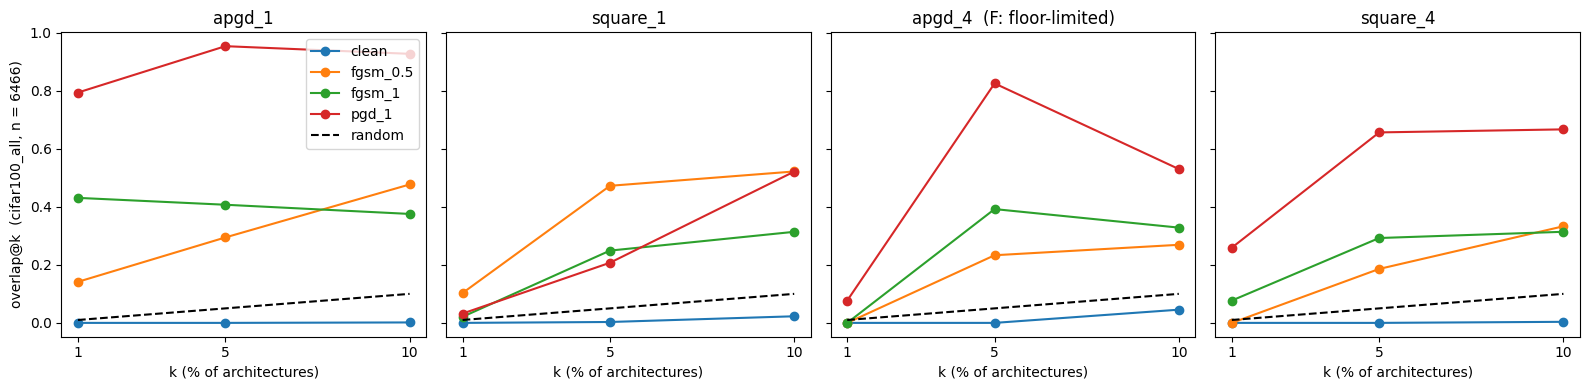

In [ ]:
# A5 — Cell 17: figure overlap@k against k (plan §11)
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, t in zip(axes, TARGETS):
    for c in CHEAP:
        ax.plot([1, 5, 10], point.loc[(t, c), ["ov1", "ov5", "ov10"]].to_numpy(), marker="o", label=c)
    ax.plot([1, 5, 10], [0.01, 0.05, 0.10], "k--", label="random")
    ax.set_title(t + ("  (F: floor-limited)" if fs[t] > 0.5 else ""))
    ax.set_xticks([1, 5, 10])
    ax.set_xlabel("k (% of architectures)")
axes[0].set_ylabel(f"overlap@k  ({TAG}, n = {len(A)})")
axes[0].legend()
plt.tight_layout()
plt.savefig(f"{OUT}a5_overlap_at_k_{TAG}.png", dpi=150)
plt.show()

In [ ]:
# A5 — Cell 18: sensitivity analysis on all architectures (plan §3)
A, TAG = df, DATASET + "_all"
print("architectures:", len(A))

architectures: 6466


In [ ]:
# A6 — Cell 22: verdicts on the analysis set and on all architectures, side by side
cols = ["ov5_lo", "tau_lo", "outcome"]
v = pd.read_csv(f"{OUT}a5_verdicts_{DATASET}.csv", index_col=[0, 1])[cols]
v_all = pd.read_csv(f"{OUT}a5_verdicts_{DATASET}_all.csv", index_col=[0, 1])[cols]
print(v.join(v_all, rsuffix="_all").round(3).to_string())

                   ov5_lo  tau_lo outcome  ov5_lo_all  tau_lo_all outcome_all
target   cheap                                                               
apgd_1   clean      0.000  -0.415       C       0.000      -0.414           C
         fgsm_0.5   0.238   0.369       C       0.236       0.369           C
         fgsm_1     0.358   0.249       B       0.355       0.249           B
         pgd_1      0.927   0.880       A       0.928       0.880           A
square_1 clean      0.000  -0.213       C       0.000      -0.212           C
         fgsm_0.5   0.425   0.443       B       0.426       0.443           B
         fgsm_1     0.210   0.244       C       0.206       0.244           C
         pgd_1      0.163   0.630       C       0.162       0.631           C
apgd_4   clean      0.000  -0.324       F       0.000      -0.327           F
         fgsm_0.5   0.196   0.060       F       0.187       0.054           F
         fgsm_1     0.346   0.176       F       0.344       0.17